# Тема 5. Дискретные распределения на примерах про музыку

СКО $=\sqrt{D(X)}$.

![Енот играет на электрогитаре в небольшой студии звукозаписи.](enot_s_gitaroy.png)

In [1]:
from math import comb, exp, factorial, sqrt

import matplotlib.pyplot as plt


def pokaz(chisla, veroyat, zagol):
    print('k   P(X = k)')
    for k, ver in zip(chisla, veroyat):
        print(f'{k:>2}  {ver:.5f}')

    plt.figure(figsize=(8, 3.5))
    plt.plot(chisla, veroyat, marker='o')
    plt.title(zagol)
    plt.xlabel('k')
    plt.ylabel('P(X = k)')
    plt.xticks(list(chisla))
    plt.ylim(bottom=0)
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()

## 1. Биномиальное распределение

На репетиции гитарист восемь раз играет вступительный аккорд. Пусть шанс сыграть его чисто в каждом дубле равен 0,75, а дубли независимы. $X$ — число чистых дублей.

$P(X=k) = C_8^k \cdot (0{,}75)^k \cdot (0{,}25)^{8-k}, \qquad k=0,\ldots,8.$

$M(X)=np,\quad D(X)=np(1-p),\quad m_0=6.$

M(X) = 6.0000
D(X) = 1.5000
СКО = 1.2247
Мода = 6
k   P(X = k)
 0  0.00002
 1  0.00037
 2  0.00385
 3  0.02307
 4  0.08652
 5  0.20764
 6  0.31146
 7  0.26697
 8  0.10011


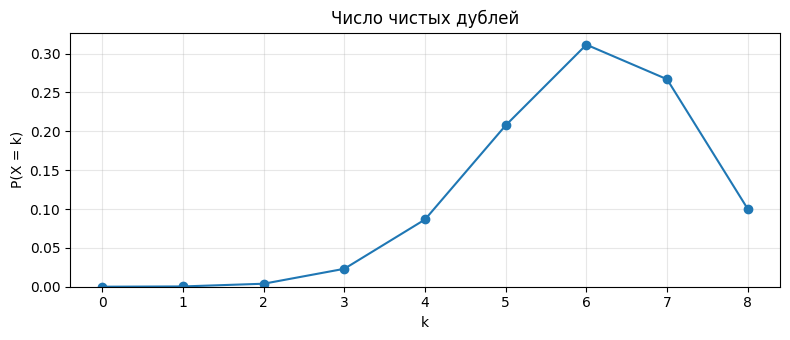

In [2]:
n = 8
p = 0.75
chisla = range(n + 1)
veroyat = [comb(n, k) * p**k * (1 - p)**(n - k) for k in chisla]

sred = n * p
disp = n * p * (1 - p)
moda = int((n + 1) * p)
print(f'M(X) = {sred:.4f}')
print(f'D(X) = {disp:.4f}')
print(f'СКО = {sqrt(disp):.4f}')
print(f'Мода = {moda}')

pokaz(chisla, veroyat, 'Число чистых дублей')

## 2. Распределение Пуассона

Во время музыкального стрима слушатели отправляют заявки на песни. В среднем приходит 2,4 заявки за 10 минут. Пусть заявки приходят независимо и с постоянной средней интенсивностью. $X$ — число заявок за 10 минут, $\lambda = 2{,}4$.

$P(X=k) = e^{-2{,}4} \frac{(2{,}4)^k}{k!}, \qquad k=0,1,2,\ldots$

$M(X)=D(X)=\lambda,\quad m_0=2.$

M(X) = 2.4000
D(X) = 2.4000
СКО = 1.5492
Мода = 2
Вероятность за пределом графика: 0.00004
k   P(X = k)
 0  0.09072
 1  0.21772
 2  0.26127
 3  0.20901
 4  0.12541
 5  0.06020
 6  0.02408
 7  0.00826
 8  0.00248
 9  0.00066
10  0.00016


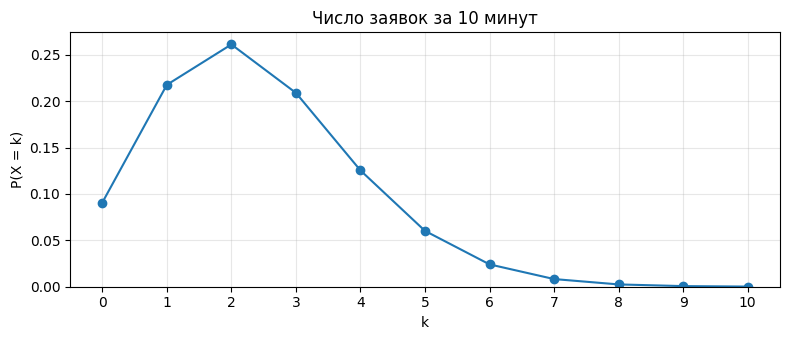

In [3]:
lamb = 2.4
chisla = range(11)
veroyat = [exp(-lamb) * lamb**k / factorial(k) for k in chisla]

sred = lamb
disp = lamb
moda = int(lamb)
print(f'M(X) = {sred:.4f}')
print(f'D(X) = {disp:.4f}')
print(f'СКО = {sqrt(disp):.4f}')
print(f'Мода = {moda}')
print(f'Вероятность за пределом графика: {1 - sum(veroyat):.5f}')

pokaz(chisla, veroyat, 'Число заявок за 10 минут')

## 3. Геометрическое распределение

Для фона в ролик нужен трек без вокала. Приложение выдаёт случайные треки из каталога, повторения возможны. При каждой попытке шанс получить трек без вокала равен 0,25 и попытки независимы. $X$ — номер попытки, на которой впервые попадётся такой трек.

$P(X=k) = (0{,}75)^{k-1} \cdot 0{,}25, \qquad k=1,2,3,\ldots$

$M(X)=1/p,\quad D(X)=(1-p)/p^2,\quad m_0=1.$

M(X) = 4.0000
D(X) = 12.0000
СКО = 3.4641
Мода = 1
Вероятность за пределом графика: 0.00317
k   P(X = k)
 1  0.25000
 2  0.18750
 3  0.14062
 4  0.10547
 5  0.07910
 6  0.05933
 7  0.04449
 8  0.03337
 9  0.02503
10  0.01877
11  0.01408
12  0.01056
13  0.00792
14  0.00594
15  0.00445
16  0.00334
17  0.00251
18  0.00188
19  0.00141
20  0.00106


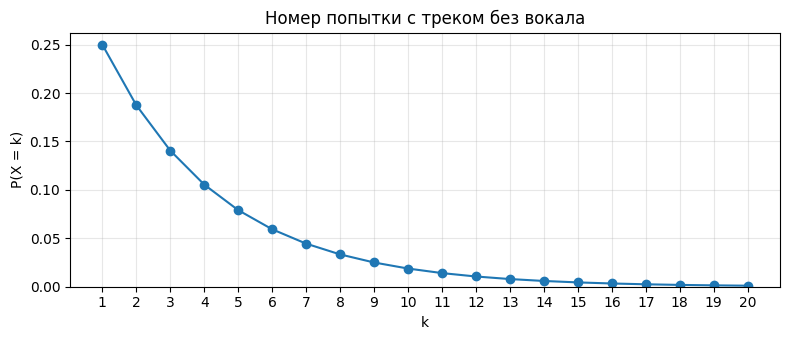

In [4]:
p = 0.25
chisla = range(1, 21)
veroyat = [(1 - p)**(k - 1) * p for k in chisla]

sred = 1 / p
disp = (1 - p) / p**2
moda = 1
print(f'M(X) = {sred:.4f}')
print(f'D(X) = {disp:.4f}')
print(f'СКО = {sqrt(disp):.4f}')
print(f'Мода = {moda}')
print(f'Вероятность за пределом графика: {1 - sum(veroyat):.5f}')

pokaz(chisla, veroyat, 'Номер попытки с треком без вокала')

## 4. Гипергеометрическое распределение

В медиатеке 15 треков, 6 записаны на концертах. Для передачи случайно выбирают четыре разных трека без возвращения. $X$ — сколько концертных записей будет среди выбранных.

$P(X=k) = \frac{C_6^k C_9^{4-k}}{C_{15}^4}, \qquad k=0,1,2,3,4.$

$N=15,\quad n=4,\quad p=6/15.$

$M(X)=np,\quad D(X)=np(1-p)\dfrac{N-n}{N-1},\quad m_0=2.$

M(X) = 1.6000
D(X) = 0.7543
СКО = 0.8685
Мода = 2
k   P(X = k)
 0  0.09231
 1  0.36923
 2  0.39560
 3  0.13187
 4  0.01099


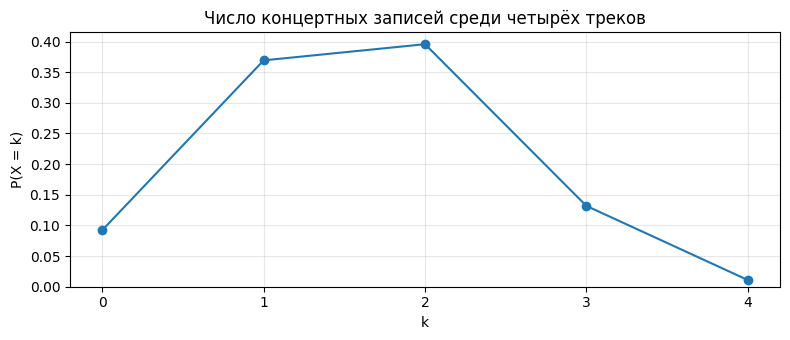

In [5]:
vsego = 15
koncert = 6
n = 4
p = koncert / vsego

chisla = range(n + 1)
veroyat = [
    comb(koncert, k) * comb(vsego - koncert, n - k) / comb(vsego, n)
    for k in chisla
]

sred = n * p
disp = n * p * (1 - p) * (vsego - n) / (vsego - 1)
moda = chisla[veroyat.index(max(veroyat))]
print(f'M(X) = {sred:.4f}')
print(f'D(X) = {disp:.4f}')
print(f'СКО = {sqrt(disp):.4f}')
print(f'Мода = {moda}')

pokaz(chisla, veroyat, 'Число концертных записей среди четырёх треков')